[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tester170/france-segformer-b0/blob/v1.0/France_SegFormer_B0.ipynb)

# **SegFormer-B0 для набора France (разметка IGN CoSIA): инференс, оценка и дообучение на своих данных (MMSegmentation 1.2.2)**

Автономный блокнот: всё нужное он разворачивает сам, заранее ничего загружать не надо. Все файлы сохраняются в папку рядом с блокнотом, в Colab это локальный диск сессии `/content`.

Модель — SegFormer-B0 (кодировщик MiT-B0 и MLP-декодер, 3,7 млн параметров), обученная на ортофотоснимках Франции с разрешением около 0,2 м по 14 классам покрытия земли палитры IGN CoSIA: здания, покрытия, вода, хвойные и лиственные деревья, кустарник, газон, посевы, пашня, виноградники, бассейны, теплицы. Одна общая модель для трёх типов местности: город (City), сельская местность (Village) и природные ландшафты (Other). На валидационных фрагментах она достигает mIoU 72,9 %, общей точности 88,6 % и κ = 0,860.

Откуда берутся файлы:
* **код конвейера** (конфигурация MMSegmentation, модули проекта, скрипты) — клонируется из репозитория GitHub на метке релиза `v1.0`;
* **веса модели** (15 МБ) и сборка MMCV — скачиваются из релиза `v1.0` с проверкой контрольной суммы SHA-256;
* **набор France** (5,4 ГБ) — скачивается по публичной ссылке Яндекс Диска, каждый файл сверяется с контрольной суммой SHA-256;
* **библиотеки** — устанавливаются в отдельное окружение Python 3.11 с версиями эксперимента (PyTorch 2.1.0 + CUDA 12.1, MMCV 2.1.0, MMEngine 0.10.7, MMSegmentation 1.2.2), окружение Colab не меняется.

Блокнот выполняет инференс по своим снимкам любого размера (раздел 2), оценку модели на валидационных фрагментах France штатным `tools/test.py` (раздел 3), дообучение на своих размеченных данных или на наборе France (разделы 4–6) и выгрузку весов и результатов (раздел 7).

Для запуска выберите *Среда выполнения → Сменить среду выполнения → GPU* (T4 достаточно), затем *Среда выполнения → Выполнить все*. До готовности к инференсу проходит около 5 минут, почти всё это время уходит на установку окружения.

## **Параметры и загрузка пакета**

Все пути отсчитываются от папки блокнота (`ROOT`). В Colab это локальный диск сессии `/content`: он очищается при завершении сессии, поэтому нужные результаты скачайте кнопками раздела 7.

In [1]:
import os, sys, json, re
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO      = 'tester170/france-segformer-b0'                # репозиторий GitHub с кодом и релизом
TAG       = 'v1.0'                                          # версия (метка релиза)
ROOT      = os.environ.get('FR_ROOT', os.getcwd())          # папка блокнота; в Colab — /content
BUNDLE    = f'{ROOT}/france-segformer-b0'                   # код и модель (из репозитория)
MY_IMAGES = f'{ROOT}/my_images'                             # свои снимки для инференса
MY_DATA   = f'{ROOT}/my_data'                               # свои размеченные данные для дообучения
RAW       = f'{ROOT}/data/France'                           # набор France с Яндекс Диска (раздел 3)
DATA_FR   = f'{ROOT}/data/france'                           # набор France в структуре MMSegmentation
DATA_OWN  = f'{ROOT}/data/my_data'                          # свои данные в структуре MMSegmentation
WORK      = f'{ROOT}/france_runs'                           # результаты
ENV       = f'{ROOT}/py311'                                 # окружение Python 3.11
PY = f'{ENV}/bin/python'
CONFIG = 'configs/france/segformer_mit-b0_1xb8-amp_france-1024x1024.py'


def run(*args, show=None, log=None):
    # команда с выводом в реальном времени; show — регулярное выражение строк, которые выводятся (None — все),
    # log — файл полного вывода; при ошибке ячейка останавливается
    import subprocess
    env = {**os.environ, 'MPLBACKEND': 'Agg', 'PYTHONUNBUFFERED': '1', 'PYTHONPATH': BUNDLE}
    p = subprocess.Popen([str(a) for a in args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                         bufsize=1, env=env, cwd=BUNDLE if Path(BUNDLE).exists() else ROOT)
    if log:
        Path(log).parent.mkdir(parents=True, exist_ok=True)
    f = open(log, 'w', encoding='utf-8') if log else None
    tail = []
    for line in p.stdout:
        if f:
            f.write(line)
        tail = (tail + [line])[-30:]
        if show is None or re.search(show, line):
            print(line, end='', flush=True)
    if f:
        f.close()
    if p.wait() != 0:
        if show is not None:
            print(''.join(tail))
        raise RuntimeError(f'команда завершилась с ошибкой (код {p.returncode}): ' + ' '.join(map(str, args)))


def download_button(label, make_file):
    # кнопка: по нажатию файл готовится (make_file() возвращает путь) и скачивается браузером
    import ipywidgets as widgets
    from IPython.display import display
    out = widgets.Output()
    button = widgets.Button(description=label, icon='download', button_style='primary', layout=widgets.Layout(width='auto'))

    def click(_):
        with out:
            path = make_file()
            print(f'{Path(path).name}: {Path(path).stat().st_size / 2 ** 20:.1f} МБ')
            if IN_COLAB:
                from google.colab import files
                files.download(path)

    button.on_click(click)
    display(widgets.VBox([button, out]))


def zip_folder(folder, name):
    import shutil
    return shutil.make_archive(f'{ROOT}/{name}', 'zip', folder)


def test_metrics(work_dir):
    # итог tools/test.py: последняя строка json-журнала запуска
    logs = sorted(Path(work_dir).glob('*/*.json'))
    return json.loads(logs[-1].read_text().strip().splitlines()[-1]) if logs else None


for d in (WORK, MY_IMAGES):
    Path(d).mkdir(parents=True, exist_ok=True)
print('папка блокнота:', ROOT)
print('свои снимки   :', MY_IMAGES)
print('свои данные   :', MY_DATA)
print('результаты    :', WORK)

папка блокнота: /content
свои снимки   : /content/my_images
свои данные   : /content/my_data
результаты    : /content/france_runs


Следующая ячейка клонирует код из репозитория на метке релиза и скачивает из релиза обученную модель (15 МБ) с проверкой контрольной суммы.

In [2]:
if not Path(BUNDLE, 'scripts', 'infer.py').exists():
    run('git', 'clone', '--quiet', '--depth', '1', '--branch', TAG, f'https://github.com/{REPO}.git', BUNDLE)
run('python3', f'{BUNDLE}/scripts/fetch.py', 'model')
CHECKPOINT = f'{BUNDLE}/checkpoints/segformer_b0_france_ep76.pth'

Note: switching to '776c3e08bb99b8ee47b6adcb4c9bd87a48b0ccd5'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

segformer_b0_france_ep76.pth (14 MB) from tester170/france-segformer-b0 release v1.0
segformer_b0_france_ep76.pth <- https://github.com/tester170/france-segformer-b0/releases/download/v1.0/segformer_b0_france_ep76.pth


## **1. Рабочее окружение**

Создаётся отдельное окружение Python 3.11 со строго зафиксированными версиями всех пакетов (`env/requirements.lock`, установка без подбора зависимостей). Первый запуск занимает 3–5 минут, повторный в той же сессии — секунды.

MMCV 2.1.0 ставится официальной сборкой OpenMMLab для PyTorch 2.1 и CUDA 12.1 из релиза репозитория. В конце проверяются версии пакетов, видеокарта, CUDA-операции MMCV и модули проекта.

In [3]:
run('bash', f'{BUNDLE}/env/setup_env.sh', ENV)

== creating Python 3.11 environment in /content/py311
Using CPython 3.11.17
Creating virtual environment with seed packages at: /content/py311
 + packaging==26.3
 + pip==26.2.2
 + setuptools==84.2.1
 + wheel==0.48.0
Activate with: source /content/py311/bin/activate
== installing pinned packages (PyTorch 2.1.0 cu121, MMEngine, MMSegmentation, ...): ~2-3 min
Using Python 3.11.17 environment at: /content/py311
Resolved 62 packages in 1.05s
Prepared 60 packages in 42.19s
Uninstalled 1 package in 13ms
Installed 60 packages in 522ms
 + addict==2.4.0
 + affine==3.0.1
 + attrs==26.1.0
 + certifi==2026.7.22
 + charset-normalizer==3.5.2
 + click==8.5.0
 + click-plugins==1.1.1.2
 + cligj==0.7.2
 + cloudpickle==3.1.2
 + contourpy==1.3.3
 + cycler==0.12.1
 + filelock==4.2.0
 + fonttools==4.67.0
 + fsspec==2026.9.0
 + ftfy==6.3.1
 + idna==3.20
 + jinja2==3.1.6
 + kiwisolver==1.5.1
 + llvmlite==0.43.0
 + markdown-it-py==4.2.0
 + markupsafe==3.0.4
 + matplotlib==3.11.2
 + mdurl==0.1.2
 + mmdet==3.3.0


## **2. Инференс по своим снимкам**

Снимки положите в папку `my_images` рядом с блокнотом (в Colab — `/content/my_images`, через панель «Файлы» слева) или задайте `UPLOAD = True`: тогда после запуска ячейки появится кнопка выбора файлов на компьютере.

Модель обучена на 8-битных RGB-ортофотоснимках Франции с разрешением около 0,2 м. Снимки с другим разрешением лучше заранее привести к 0,2 м на пиксель. Подходят GeoTIFF/TIFF, JP2, IMG, VRT, JPG, PNG, BMP и WEBP любого размера. У многоканальных растров номера каналов R, G, B задаются в `BANDS`.

Для каждого снимка сохраняются:
* `<имя>_cosia` — маска с кодами классов CoSIA (таблица — в разделе 4);
* `<имя>_color.png` — цветная маска в палитре CoSIA;
* `<имя>_overlay.jpg` — маска поверх снимка;
* `<имя>_preview.jpg` — снимок и маска рядом в уменьшенном виде.

Для георастров маска записывается в GeoTIFF с той же проекцией, привязкой и встроенной палитрой CoSIA (в QGIS цвета классов видны сразу), для обычных снимков — в PNG.

`FP16 = True` включает вычисления в половинной точности. Для такой малой модели заметного ускорения они не дают, поэтому по умолчанию выключены.

In [4]:
UPLOAD  = True             # True — выбрать снимки на компьютере кнопкой
OUT_OWN = f'{WORK}/my_images'
BANDS   = ''               # номера каналов R G B растра, например '1 2 3'; '' — первые три
FP16    = False

import shutil
if UPLOAD and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        shutil.rmtree(MY_IMAGES); Path(MY_IMAGES).mkdir()
        for name, content in uploaded.items():
            Path(MY_IMAGES, name).write_bytes(content)
own = sorted(p.name for p in Path(MY_IMAGES).iterdir() if p.is_file())
print('снимки:', own if own else f'нет — положите снимки в {MY_IMAGES} или задайте UPLOAD = True и запустите ячейку снова')
if own:
    args = ['--input', MY_IMAGES, '--out', OUT_OWN, '--checkpoint', CHECKPOINT, '--overlay']
    args += ['--bands', *BANDS.split()] if BANDS else []
    args += ['--fp16'] if FP16 else []
    run(PY, f'{BUNDLE}/scripts/infer.py', *args)

Saving France_Val.PNG to France_Val.PNG
снимки: ['France_Val.PNG']
France_Val.PNG: 1184 x 918 px, 0.7 s -> France_Val_cosia.png (Посевы 33.3 %, Газон, луг 29.3 %, Лиственные деревья 19.1 %, Виноградник 4.6 %)


France_Val_preview.jpg


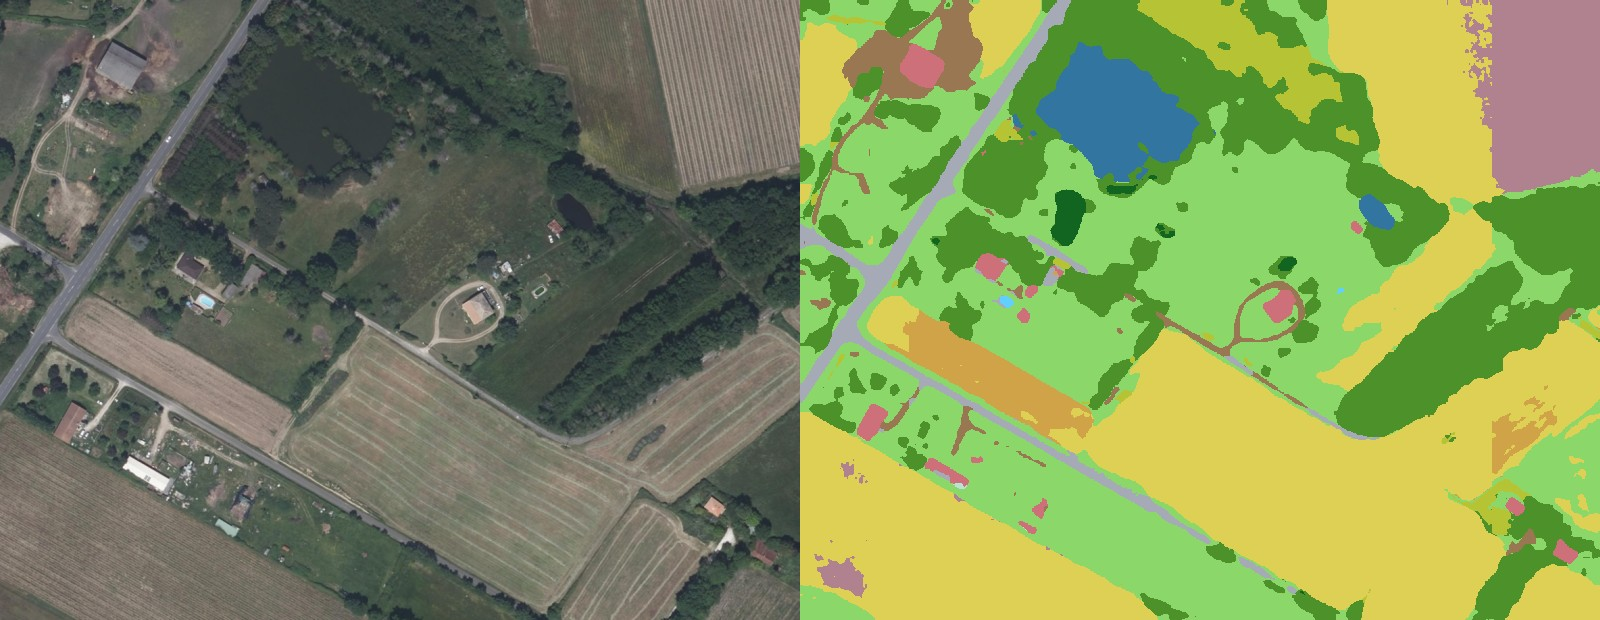

In [5]:
from IPython.display import Image, display
for p in sorted(Path(OUT_OWN).glob('*_preview.jpg'))[:5]:
    print(p.name); display(Image(str(p), width=1100))
if any(Path(OUT_OWN).glob('*_cosia*')):
    download_button('Скачать маски своих снимков (.zip)', lambda: zip_folder(OUT_OWN, 'my_images_masks'))

## **3. Оценка модели на валидационных фрагментах France**

Раздел проверяет модель на наборе, на котором она обучалась. Набор France (16 фрагментов ортофотоснимков и разметка CoSIA, 5,4 ГБ) скачивается по публичной ссылке Яндекс Диска, учётная запись не нужна. Затем `scripts/prepare_data.py` раскладывает его в структуру MMSegmentation: 12 обучающих фрагментов режутся на плитки 2048 × 2048, 4 валидационных фрагмента сохраняются целиком. Скачивание занимает несколько минут, подготовка около 3 минут.

Оценка выполняется штатным `tools/test.py` MMSegmentation 1.2.2 с конфигурацией репозитория: валидационные фрагменты целиком, скользящее окно 1024 × 1024 с шагом 768. Ожидаемый результат: mIoU 72,90 %, общая точность (aAcc) 88,62 %. На T4 оценка занимает около 2 минут.

Раздел можно пропустить (`EVAL_FRANCE = False`). Подготовленный здесь набор нужен и для дообучения: в разделе 5 новая модель проверяется на France, чтобы было видно, не потеряла ли она качество на исходных данных.

Набор France составлен из ортофотоснимков и разметки CoSIA (Couverture du Sol par Intelligence Artificielle) национального института географической и лесной информации Франции (IGN), открытая лицензия Etalab 2.0. Разметка CoSIA создана нейросетью, поэтому метрики показывают согласие модели с CoSIA.

In [6]:
EVAL_FRANCE = os.environ.get('FR_EVAL', '1') == '1'
OUT_EVAL = f'{WORK}/evaluation_france'
if EVAL_FRANCE:
    run('python3', f'{BUNDLE}/scripts/fetch.py', 'dataset', '--out', RAW)
    run(PY, f'{BUNDLE}/scripts/prepare_data.py', '--src', RAW, '--out', DATA_FR, '--workers', 2)
    run(PY, f'{BUNDLE}/tools/test.py', CONFIG, CHECKPOINT, '--work-dir', OUT_EVAL,
        '--cfg-options', f'test_dataloader.dataset.data_root={DATA_FR}',
        show=r'^[|+]|Iter\(test\)', log=f'{WORK}/evaluation_france.log')
    m = test_metrics(OUT_EVAL)
    print(f"\nmIoU {m['mIoU']:.2f} % (ожидается 72.90), mDice {m['mDice']:.2f} %, общая точность {m['aAcc']:.2f} %")
else:
    print('оценка на France пропущена (EVAL_FRANCE = False)')

France dataset, 32 files, 5.4 GB, from https://disk.yandex.ru/d/k1HfK1f8eh27Yw
[1/32] /City/fragment_WGS84_11197x9308_z19_48.60012_2.57135.tif (298 MB)
  4/298 MB (2.6 MB/s)
  36/298 MB (10.7 MB/s)
  68/298 MB (13.1 MB/s)
  96/298 MB (14.1 MB/s)
  128/298 MB (14.8 MB/s)
  156/298 MB (15.2 MB/s)
  188/298 MB (15.5 MB/s)
  220/298 MB (15.7 MB/s)
  248/298 MB (15.9 MB/s)
  280/298 MB (16.0 MB/s)
  298/298 MB (16.1 MB/s)
[2/32] /City/fragment_WGS84_11197x9308_z19_48.60012_2.57135_indexed.tif (4 MB)
[3/32] /City/fragment_WGS84_12547x9562_z19_48.91960_2.36917.tif (343 MB)
  4/343 MB (2.6 MB/s)
  40/343 MB (11.1 MB/s)
  76/343 MB (13.4 MB/s)
  112/343 MB (14.4 MB/s)
  148/343 MB (15.0 MB/s)
  184/343 MB (14.7 MB/s)
  220/343 MB (15.0 MB/s)
  256/343 MB (15.0 MB/s)
  292/343 MB (15.2 MB/s)
  328/343 MB (15.4 MB/s)
  343/343 MB (15.5 MB/s)
[4/32] /City/fragment_WGS84_12547x9562_z19_48.91960_2.36917_indexed.tif (4 MB)
[5/32] /City/fragment_WGS84_12832x9581_z19_48.95591_2.90781.tif (352 MB)
  4/3

Пример: модель распознаёт один валидационный фрагмент из пригорода Парижа целиком. Слева направо — снимок, разметка CoSIA и результат модели в уменьшенном виде.

fragment_WGS84_12832x9581_z19_48.95591_2.90781.tif: 12832 x 9581 px, 22.6 s -> fragment_WGS84_12832x9581_z19_48.95591_2.90781_cosia.tif (Непроницаемое покрытие 34.6 %, Газон, луг 25.7 %, Здание 21.6 %, Лиственные деревья 12.9 %)


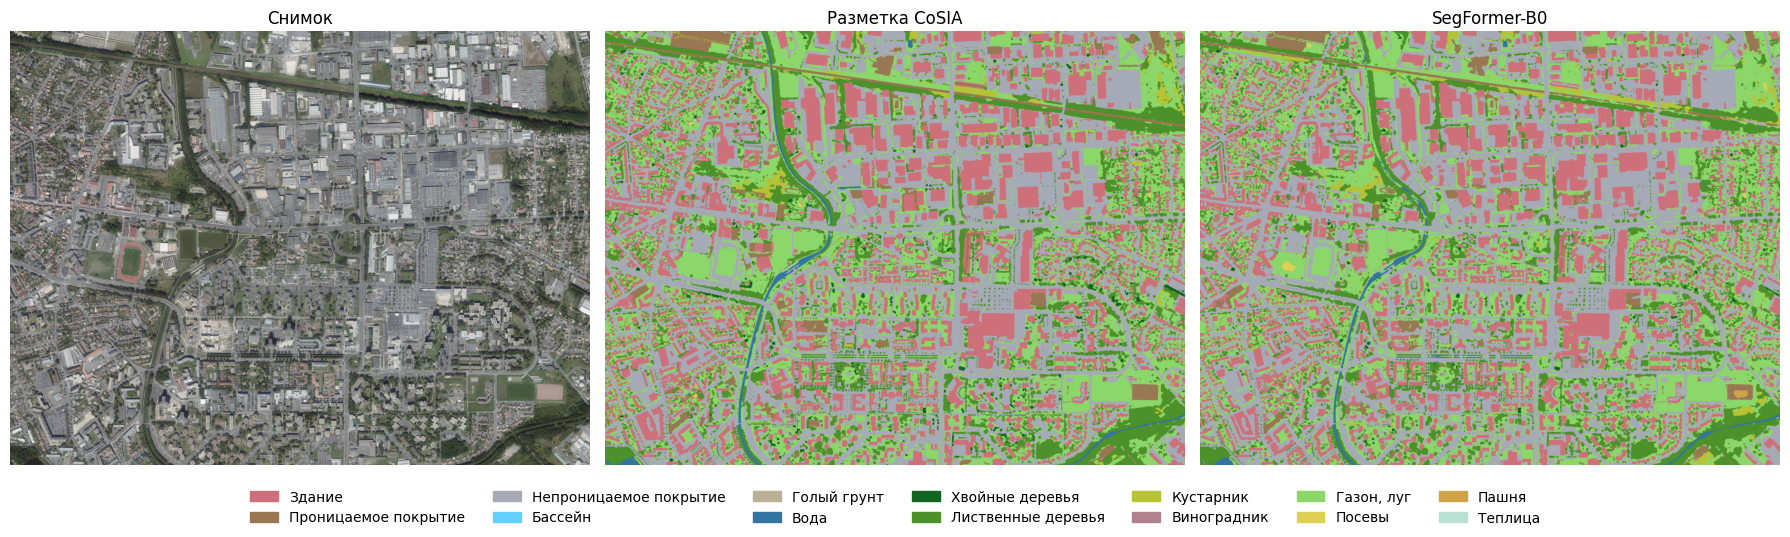

In [7]:
import numpy as np
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
PILImage.MAX_IMAGE_PIXELS = None
classes = json.loads(Path(BUNDLE, 'splits', 'split_v1.json').read_text(encoding='utf-8'))['classes']
lut = np.zeros((256, 3), np.uint8)
for c in classes:
    lut[c['cosia_id']] = c['color']
example = sorted(Path(RAW).glob('City/*48.95591_2.90781.tif'))
if example:
    ex = example[0]
    run(PY, f'{BUNDLE}/scripts/infer.py', '--input', ex, '--out', f'{WORK}/example', '--checkpoint', CHECKPOINT)
    img = PILImage.open(ex).convert('RGB').reduce(8)
    ref = PILImage.fromarray(lut[np.array(PILImage.open(str(ex)[:-4] + '_indexed.tif'))]).reduce(8)
    pred = PILImage.open(f'{WORK}/example/{ex.stem}_color.png').reduce(8)
    fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
    for a, im, t in zip(ax, (img, ref, pred), ('Снимок', 'Разметка CoSIA', 'SegFormer-B0')):
        a.imshow(im); a.set_title(t); a.axis('off')
    fig.legend(handles=[Patch(color=np.array(c['color']) / 255, label=c['name_ru']) for c in classes],
               loc='lower center', ncol=7, frameon=False)
    plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()
else:
    print('набор France не скачан (раздел 3 пропущен)')

## **4. Свои данные для дообучения**

Размеченные данные положите в папку `my_data` рядом с блокнотом (в Colab — `/content/my_data`). Удобнее всего упаковать папку в архив `my_data.zip`: задайте `UPLOAD_DATA = True`, и после запуска ячейки появится кнопка выбора архива, либо положите архив рядом с блокнотом через панель «Файлы».

Структура папки (маска называется так же, как её снимок, отличается только расширение):
```
my_data/
├── train/                 обучающая часть
│   ├── images/            снимки
│   └── masks/             маски
└── val/                   проверочная часть (необязательно)
    ├── images/
    └── masks/
```

Если папки `val` нет, для проверки откладывается каждый пятый снимок обучающей части (по алфавиту), поэтому снимков должно быть не меньше двух.

**Снимки:** GeoTIFF/TIFF, JP2, IMG, VRT, JPG, PNG, BMP или WEBP, 8-битные RGB (у многоканальных растров номера каналов задаются в `BANDS_OWN`), разрешение около 0,2 м, любой размер.

**Маски:** файлы PNG или TIFF того же размера, что и снимок, пиксель в пиксель. Подходят два вида масок: одноканальная маска с кодами классов CoSIA (таблица ниже) или цветная маска в палитре CoSIA, например маска, полученная из сервиса CoSIA. Неразмеченные области помечайте кодом 255 (у цветной маски — любым цветом не из палитры). Код 0 означает класс «здание», а не «нет разметки».

Размечать все 14 классов не обязательно: модель дообучается на тех классах, что есть в масках.

Ячейка проверяет данные (наличие маски у каждого снимка, совпадение размеров, коды или цвета классов) и раскладывает их в структуру MMSegmentation: обучающие снимки режутся на плитки 2048 × 2048, проверочные сохраняются целиком. В выводе — размер каждого снимка, доля размеченных пикселей и состав классов.

In [8]:
UPLOAD_DATA = False   # True — выбрать архив my_data.zip на компьютере кнопкой
BANDS_OWN   = ''      # номера каналов R G B растров, например '1 2 3'; '' — первые три

classes = json.loads(Path(BUNDLE, 'splits', 'split_v1.json').read_text(encoding='utf-8'))['classes']
print('коды классов CoSIA в масках (цвет RGB для цветных масок):')
for c in classes:
    print(f"  {c['cosia_id']:2d}  {c['name_ru']:24s} {tuple(c['color'])}")
print('  255 нет разметки')
if UPLOAD_DATA and IN_COLAB:
    from google.colab import files
    for name, content in files.upload().items():
        Path(ROOT, 'my_data.zip').write_bytes(content)
if not Path(MY_DATA).exists() and Path(f'{MY_DATA}.zip').exists():
    import zipfile
    with zipfile.ZipFile(f'{MY_DATA}.zip') as z:
        top = {n.split('/')[0] for n in z.namelist() if n.strip('/')}
        z.extractall(ROOT if top == {'my_data'} else MY_DATA)
    print('архив распакован:', MY_DATA)
OWN_READY = Path(MY_DATA).exists()
if OWN_READY:
    args = ['--data', MY_DATA, '--out', DATA_OWN] + (['--bands', *BANDS_OWN.split()] if BANDS_OWN else [])
    run(PY, f'{BUNDLE}/scripts/prepare_own.py', *args)
else:
    print(f'папки {MY_DATA} нет: положите туда свои данные (или архив my_data.zip) и запустите ячейку снова')

коды классов CoSIA в масках (цвет RGB для цветных масок):
   0  Здание                   (206, 112, 121)
   1  Проницаемое покрытие     (152, 119, 82)
   2  Непроницаемое покрытие   (166, 170, 183)
   3  Бассейн                  (98, 208, 255)
   4  Голый грунт              (187, 176, 150)
   5  Вода                     (51, 117, 161)
   7  Хвойные деревья          (18, 100, 33)
   8  Лиственные деревья       (76, 145, 41)
   9  Кустарник                (181, 195, 53)
  10  Виноградник              (176, 130, 144)
  11  Газон, луг               (140, 215, 106)
  12  Посевы                   (222, 207, 85)
  13  Пашня                    (208, 163, 73)
  14  Теплица                  (185, 226, 212)
  255 нет разметки
папки /content/my_data нет: положите туда свои данные (или архив my_data.zip) и запустите ячейку снова


## **5. Дообучение**

Дообучение включается параметром `TRAIN = True`. По умолчанию оно выключено, чтобы «Выполнить все» не запускало долгий процесс.

Обучение начинается с весов модели из релиза (или с любой точки этой модели, путь в `INIT`) на своих данных из раздела 4, а если их нет — на наборе France из раздела 3. Запускается штатный `tools/train.py` MMSegmentation с конфигурацией эксперимента: патчи 1024 × 1024, масштаб 0,75–1,5, повороты на 90° и отражения, мягкие цветовые искажения, батч 8, смешанная точность fp16.

Скорость обучения по умолчанию `LR = 1.5e-5` — в четыре раза ниже, чем при обучении модели с нуля (`6e-5`): дообучение начинается с уже обученной модели, и большой шаг разрушил бы её признаки. Разогрев сокращён до 100 итераций.

Проверка выполняется каждые `VAL_EVERY` итераций. Скорость обучения снижается вдвое после 5 проверок без роста mIoU, обучение останавливается после 12 таких проверок или по достижении `ITERS` итераций. Лучшая модель сохраняется как `best_mIoU_iter_N.pth`. На T4 итерация с батчем 8 занимает около 1,5 с.

Если среда выполнения перезапустится без отключения сессии, повторный запуск ячейки с тем же `RUN_NAME` продолжит обучение с последней сохранённой точки.

In [9]:
TRAIN     = os.environ.get('FR_TRAIN', '0') == '1'     # замените на True, чтобы дообучать
INIT      = os.environ.get('FR_INIT', 'release')       # 'release' — модель из релиза, или путь к .pth
RUN_NAME  = os.environ.get('FR_RUN', 'finetune')
LR        = float(os.environ.get('FR_LR', 1.5e-5))
ITERS     = int(os.environ.get('FR_ITERS', 4000))
VAL_EVERY = int(os.environ.get('FR_VAL_EVERY', 500))
BATCH     = int(os.environ.get('FR_BATCH', 8))
WARMUP    = 100
RUN_DIR = f'{WORK}/runs/{RUN_NAME}'
TRAIN_DATA = DATA_OWN if Path(DATA_OWN, 'img_dir', 'train').exists() else DATA_FR
if TRAIN and Path(TRAIN_DATA, 'img_dir', 'train').exists():
    print('данные для дообучения:', TRAIN_DATA)
    resume = Path(RUN_DIR, 'last_checkpoint').exists()
    opts = [f'train_dataloader.dataset.data_root={TRAIN_DATA}', f'val_dataloader.dataset.data_root={TRAIN_DATA}',
            f'test_dataloader.dataset.data_root={TRAIN_DATA}', f'train_dataloader.batch_size={BATCH}',
            f'optim_wrapper.optimizer.lr={LR}', f'train_cfg.max_iters={ITERS}', f'train_cfg.val_interval={VAL_EVERY}',
            f'default_hooks.checkpoint.interval={VAL_EVERY}', f'param_scheduler.0.end={WARMUP}',
            f'custom_hooks.0.start_iter={WARMUP}',
            'load_from=None' if resume else f"load_from={CHECKPOINT if INIT == 'release' else INIT}"]
    run(PY, f'{BUNDLE}/tools/train.py', CONFIG, '--work-dir', RUN_DIR, *(['--resume'] if resume else []),
        '--cfg-options', *opts, show=r'Iter\(train\) \[ *\d*00/|Iter\(val\)|best checkpoint|plateau',
        log=f'{RUN_DIR}.log')
else:
    print('дообучение выключено (TRAIN = False)' if not TRAIN else 'нет данных: см. разделы 3 и 4')

дообучение выключено (TRAIN = False)


Лучшая модель запуска оценивается на проверочной части своих данных и, если в разделе 3 был подготовлен набор France, на его валидационных фрагментах. Так видно, что модель выучила новое и не потеряла качество на исходном наборе. Для сравнения на своих данных оценивается и модель из релиза.

In [10]:
best = sorted(Path(RUN_DIR).glob('best_mIoU_iter_*.pth'), key=lambda p: int(p.stem.split('_')[-1]))
NEW_CKPT = str(best[-1]) if best else None
if NEW_CKPT:
    print('лучшая модель запуска:', NEW_CKPT)
    checks = [(DATA_OWN, NEW_CKPT, 'свои данные (проверочная часть), дообученная модель'),
              (DATA_OWN, CHECKPOINT, 'свои данные (проверочная часть), модель из релиза'),
              (DATA_FR, NEW_CKPT, 'France (валидационные фрагменты), дообученная модель')]
    for root, ckpt, name in checks:
        if Path(root, 'img_dir', 'val').exists() and any(Path(root, 'img_dir', 'val').iterdir()):
            out = f"{RUN_DIR}/evaluation_{Path(root).name}_{'release' if ckpt == CHECKPOINT else 'finetuned'}"
            run(PY, f'{BUNDLE}/tools/test.py', CONFIG, ckpt, '--work-dir', out,
                '--cfg-options', f'test_dataloader.dataset.data_root={root}', show=r'^$', log=f'{out}.log')
            m = test_metrics(out)
            print(f"{name}: mIoU {m['mIoU']:.2f} %, mDice {m['mDice']:.2f} %, общая точность {m['aAcc']:.2f} %")
else:
    print('в папке запуска нет лучшей модели: обучение не запускалось или не дошло до первой проверки')

в папке запуска нет лучшей модели: обучение не запускалось или не дошло до первой проверки


## **6. Применение дообученной модели**

Ячейка обрабатывает снимки из `my_images` лучшей моделью последнего дообучения (или моделью, путь к которой указан в `APPLY_CHECKPOINT`). Маски сохраняются в отдельную папку `my_images_finetuned`, чтобы их можно было сравнить с масками модели из релиза.

In [11]:
APPLY_CHECKPOINT = NEW_CKPT          # путь к .pth; None — дообученной модели нет
OUT_APPLY = f'{WORK}/my_images_finetuned'
if APPLY_CHECKPOINT and own:
    args = ['--input', MY_IMAGES, '--out', OUT_APPLY, '--checkpoint', APPLY_CHECKPOINT, '--overlay']
    args += ['--bands', *BANDS.split()] if BANDS else []
    args += ['--fp16'] if FP16 else []
    run(PY, f'{BUNDLE}/scripts/infer.py', *args)
    for p in sorted(Path(OUT_APPLY).glob('*_preview.jpg'))[:5]:
        print(p.name); display(Image(str(p), width=1100))
    download_button('Скачать маски дообученной модели (.zip)', lambda: zip_folder(OUT_APPLY, 'my_images_finetuned_masks'))
else:
    print('нет дообученной модели или своих снимков в my_images')

нет дообученной модели или своих снимков в my_images


## **7. Скачать веса и результаты**

Кнопки ниже скачивают файлы с диска сессии на компьютер. Веса — чекпойнт MMSegmentation 1.2.2 (`state_dict` и метаданные классов). Для работы с ними вне блокнота удобнее архив «модель для MMSegmentation»: в нём веса, конфигурация, модули проекта, таблица классов, скрипты инференса и описание окружения.

Кнопки дообученной модели появляются, если в разделе 5 было обучение. Архив результатов содержит маски, метрики оценки, журналы и папки запусков.

In [12]:
import zipfile


def model_package(ckpt=CHECKPOINT, name='segformer_b0_france_model'):
    # веса + всё, что нужно для работы с ними в MMSegmentation 1.2.2
    path = f'{ROOT}/{name}.zip'
    names = ['README.md', 'MODEL_CARD_RU.md', 'splits/split_v1.json', 'env/setup_env.sh', 'env/check_env.py',
             'env/requirements.lock', 'env/assets.json', 'scripts/fetch.py', 'scripts/infer.py', 'tools/test.py']
    names += sorted(p.relative_to(BUNDLE).as_posix() for p in Path(BUNDLE, 'configs').rglob('*.py'))
    names += sorted(p.relative_to(BUNDLE).as_posix() for p in Path(BUNDLE, 'france_mmseg').glob('*.py'))
    with zipfile.ZipFile(path, 'w', zipfile.ZIP_DEFLATED, strict_timestamps=False) as z:
        z.write(ckpt, f'checkpoints/{Path(ckpt).name}')
        for n in names:
            z.write(Path(BUNDLE, n), n)
    return path


download_button('Веса модели из релиза (.pth, 15 МБ)', lambda: CHECKPOINT)
download_button('Модель для MMSegmentation: веса, конфигурация, классы (.zip)', model_package)
runs_best = sorted(Path(WORK, 'runs').glob('*/best_mIoU_iter_*.pth'), key=lambda p: p.stat().st_mtime)
if runs_best:
    download_button(f'Дообученная модель: {runs_best[-1].parent.name}/{runs_best[-1].name}', lambda: str(runs_best[-1]))
    download_button('Дообученная модель для MMSegmentation (.zip)',
                    lambda: model_package(str(runs_best[-1]), f'segformer_b0_france_{runs_best[-1].parent.name}_model'))
download_button('Все результаты (.zip)', lambda: zip_folder(WORK, 'france_segformer_results'))

## **Примечания**

**Воспроизводимость.** Версии библиотек, код, конфигурация, веса и предобработка совпадают с экспериментом. Оценка в разделе 3 повторяет результат эксперимента до сотых (mIoU 72,90 %). На другой видеокарте (T4, L4 или A100 вместо RTX 3090) возможны расхождения в отдельных пикселях из-за порядка вычислений, на метриках они не сказываются.

**Память.** Оценка фрагмента в 120 млн пикселей занимает около 4,5 ГБ видеопамяти: модель накапливает предсказания окон полосами, а не для всего фрагмента сразу. Обучение с батчем 8 в fp16 занимает около 8 ГБ. На GPU с меньшей памятью уменьшите `BATCH`.

**Лицензии.** Ортофотоснимки и разметка CoSIA — данные IGN (открытая лицензия Etalab 2.0). Кодировщик MiT-B0 предобучен на наборе LoveDA. Модель SegFormer: E. Xie et al., NeurIPS 2021.

**Пакет** клонируется в папку `france-segformer-b0`: `configs/france/` — конфигурация MMSegmentation; `france_mmseg/` — потоковый скользящий инференс, повороты и отражения, управление скоростью обучения; `tools/` — штатные `train.py` и `test.py` MMSegmentation; `scripts/` — загрузка файлов, подготовка набора France и своих данных, инференс; `env/` — установка и проверка окружения; `splits/` — разбиение набора и таблица классов.